# Freeman Chain Code Boundary Representation (NumPy Only)
**Objective:** Extract the outer boundary of a binary object and encode its contour using **8-Directional Freeman Chain Code**, along with the **First Difference** (rotation-invariant representation) and **Shape Number**, implemented purely in **NumPy**.

### Mathematical & Directional Convention
In an **8-connected Freeman Chain Code**, each step from boundary pixel $(r_k, c_k)$ to $(r_{k+1}, c_{k+1})$ is assigned a direction code $d_k \in \{0, 1, 2, 3, 4, 5, 6, 7\}$ counter-clockwise starting from East:

| Code | Direction | $(\Delta r, \Delta c)$ | Code | Direction | $(\Delta r, \Delta c)$ |
|:---:|:---:|:---:|:---:|:---:|:---:|
| **0** | East | $(0, +1)$ | **4** | West | $(0, -1)$ |
| **1** | North-East | $(-1, +1)$ | **5** | South-West | $(+1, -1)$ |
| **2** | North | $(-1, 0)$ | **6** | South | $(+1, 0)$ |
| **3** | North-West | $(-1, -1)$ | **7** | South-East | $(+1, +1)$ |

* **First Difference (Rotation Invariant):** $\Delta d_k = (d_{k+1} - d_k) \pmod 8$
* **Shape Number:** The cyclic shift of the First Difference sequence that forms the smallest integer magnitude.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a binary image (64x64) containing a closed geometric shape
N = 64
binary_img = np.zeros((N, N), dtype=np.uint8)

# Draw a filled L-shaped / stepped polygon for clear directional transitions
binary_img[14:48, 16:32] = 1
binary_img[32:48, 16:48] = 1
# Add a diagonal chamfer corner
for i in range(6):
    binary_img[14 + i, 16 : 16 + (6 - i)] = 0

# 2. 8-Directional Freeman Chain Code Lookup Tables (Counter-Clockwise from East)
# Index 0..7 -> (dr, dc)
DIR_TO_OFFSET = [
    ( 0,  1),  # 0: East
    (-1,  1),  # 1: North-East
    (-1,  0),  # 2: North
    (-1, -1),  # 3: North-West
    ( 0, -1),  # 4: West
    ( 1, -1),  # 5: South-West
    ( 1,  0),  # 6: South
    ( 1,  1),  # 7: South-East
]
OFFSET_TO_DIR = {offset: code for code, offset in enumerate(DIR_TO_OFFSET)}


def trace_freeman_chain_code(binary: np.ndarray):
    """Moore-Neighbor Contour Tracing returning boundary coordinates and 8-direction Freeman Chain Code."""
    padded = np.pad(binary, pad_width=1, mode="constant", constant_values=0)

    # Find top-most, left-most foreground pixel as start point
    fg_rows, fg_cols = np.where(padded == 1)
    start = (int(fg_rows[0]), int(fg_cols[0]))

    boundary = [start]
    # Initial backtrack direction is West (code 4) since we scanned top-to-bottom, left-to-right
    backtrack_dir = 4
    curr = start

    while True:
        # Search 8 neighbors clockwise starting just after backtrack direction
        found_next = False
        for step in range(1, 9):
            # Clockwise scan corresponds to decrementing CCW direction index mod 8
            check_dir = (backtrack_dir - step) % 8
            dr, dc = DIR_TO_OFFSET[check_dir]
            nr, nc = curr[0] + dr, curr[1] + dc

            if padded[nr, nc] == 1:
                next_pt = (nr, nc)
                # Next backtrack points back toward the pixel we came from
                backtrack_dir = (check_dir + 4) % 8
                curr = next_pt
                found_next = True
                break

        if not found_next or curr == start:
            break
        boundary.append(curr)

    # Convert consecutive boundary points into Freeman Chain Code sequence
    chain_code = []
    num_pts = len(boundary)
    for k in range(num_pts):
        r1, c1 = boundary[k]
        r2, c2 = boundary[(k + 1) % num_pts]
        chain_code.append(OFFSET_TO_DIR[(r2 - r1, c2 - c1)])

    # Remove 1-pixel padding offset from coordinates
    boundary_unpadded = np.array([(r - 1, c - 1) for r, c in boundary], dtype=np.int32)
    return boundary_unpadded, np.array(chain_code, dtype=np.int32)


def compute_first_difference_and_shape_number(chain_code: np.ndarray):
    """Computes rotation-invariant First Difference and canonical Shape Number."""
    rolled = np.roll(chain_code, -1)
    first_diff = (rolled - chain_code) % 8

    # Find lexicographically smallest cyclic shift for the Shape Number
    n = len(first_diff)
    shifts = [np.roll(first_diff, -i) for i in range(n)]
    shape_number = min(shifts, key=lambda arr: tuple(arr.tolist()))
    return first_diff, shape_number


def reconstruct_from_chain_code(start_pt: tuple, chain_code: np.ndarray, shape: tuple) -> np.ndarray:
    """Reconstructs the boundary image purely from the start coordinate and chain code."""
    canvas = np.zeros(shape, dtype=np.uint8)
    r, c = start_pt
    canvas[r, c] = 1
    for code in chain_code:
        dr, dc = DIR_TO_OFFSET[int(code)]
        r += dr
        c += dc
        canvas[r, c] = 1
    return canvas


# Execute Chain Code Extraction & Verification
boundary_pts, freeman_code = trace_freeman_chain_code(binary_img)
first_diff, shape_num = compute_first_difference_and_shape_number(freeman_code)
reconstructed_boundary = reconstruct_from_chain_code(tuple(boundary_pts[0]), freeman_code, binary_img.shape)

print(f"Start Pixel (row, col) : {tuple(boundary_pts[0])}")
print(f"Boundary Length        : {len(freeman_code)} pixels")
print(f"Freeman Chain Code     : {''.join(map(str, freeman_code))}")
print(f"First Difference       : {''.join(map(str, first_diff))}")
print(f"Shape Number           : {''.join(map(str, shape_num))}")

Start Pixel (row, col) : (14, 22)
Boundary Length        : 121 pixels
Freeman Chain Code     : 0000000006666666666666666670000000000000006666666666666664444444444444444444444444444444222222222222222222222222222111111
First Difference       : 0000000060000000000000000110000000000000060000000000000060000000000000000000000000000006000000000000000000000000007000007
Shape Number           : 0000000000000000000000000000006000000000000000000000000007000007000000006000000000000000011000000000000006000000000000006


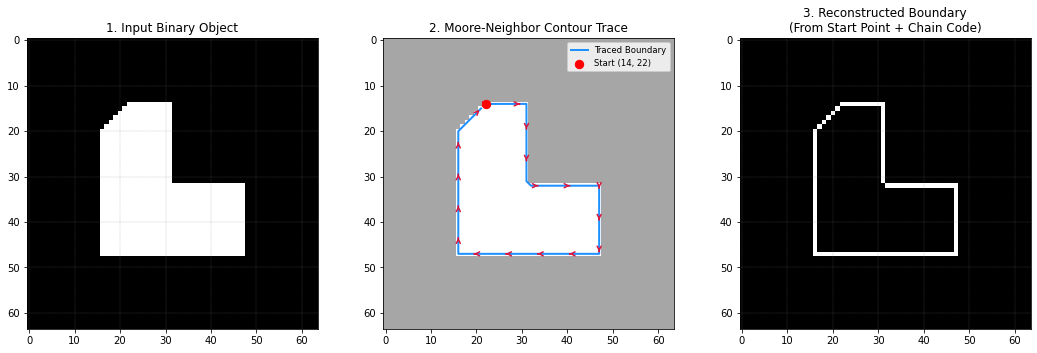

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

# Panel 1: Input Binary Object
axes[0].imshow(binary_img, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("1. Input Binary Object")
axes[0].grid(True, which="both", color="gray", linestyle=":", linewidth=0.4)

# Panel 2: Traced Contour with Start Point & Direction Arrows
axes[1].imshow(binary_img, cmap="gray", alpha=0.35, vmin=0, vmax=1)
axes[1].plot(boundary_pts[:, 1], boundary_pts[:, 0], color="dodgerblue", linewidth=2, label="Traced Boundary")
axes[1].scatter(boundary_pts[0, 1], boundary_pts[0, 0], color="red", s=70, zorder=5, label=f"Start {tuple(boundary_pts[0])}")

# Draw sample direction arrows along contour
step = max(1, len(boundary_pts) // 16)
for idx in range(0, len(boundary_pts) - 1, step):
    r0, c0 = boundary_pts[idx]
    r1, c1 = boundary_pts[idx + 1]
    axes[1].annotate(
        "", xy=(c1, r1), xytext=(c0, r0),
        arrowprops=dict(arrowstyle="->", color="crimson", lw=1.5)
    )
axes[1].set_title("2. Moore-Neighbor Contour Trace")
axes[1].legend(loc="upper right", fontsize=8.5)

# Panel 3: Reconstructed Boundary from Chain Code Only
axes[2].imshow(reconstructed_boundary, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("3. Reconstructed Boundary\n(From Start Point + Chain Code)")
axes[2].grid(True, which="both", color="gray", linestyle=":", linewidth=0.4)

plt.tight_layout()
plt.show()